In [35]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils
# noinspection PyUnresolvedReferences
from utils import artificializer

# noinspection PyUnresolvedReferences
from models import bom
# noinspection PyUnresolvedReferences
from models import hgm

In [36]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/import/models/hgm.py'>

In [37]:
default_hyperparameters = {
	'max_epochs': 2048,
	'max_patience': 2048 / 4,
	'learning_rate': 1E-1,
	'w1_reg_lambda': 1E-3,
	'w2_reg_lambda': 1E-5,
	'ccadiag_lambda': 0.6,
	'ccaunit_lambda': 1.0 - 0.6,
	'loss1_lambda': 0.5,
	'loss2_lambda': 1.0 - 0.5,
	'dimensions': 2
}

# Functions

In [38]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

In [39]:
def train_model(model, splits, N, B_ll, B_hl, hyperparams=None):
	#region hyperparamters ===============================================================
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	global default_hyperparameters
	hyperparameters = default_hyperparameters.copy()
	if hyperparams is not None:
		for key in hyperparams:
			if key in hyperparameters.keys():
				hyperparameters[key] = hyperparams[key]
			else:
				print(f'Warning: Parameter {key} not recognized.')

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']

	learning_rate = hyperparameters['learning_rate']

	n_dimensions = hyperparameters['dimensions']

	lambdas = Lambdas(
		loss_lambdas=(hyperparameters['loss1_lambda'], hyperparameters['loss2_lambda']),
		reg_lambdas=(hyperparameters['w1_reg_lambda'], hyperparameters['w2_reg_lambda']),
		cca_lambdas=(hyperparameters['ccadiag_lambda'], hyperparameters['ccaunit_lambda'])
	)
	#endregion ===========================================================================

	n_neurons = N.shape[1]
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# training loop ==============================
	params_per_split = list()
	(losses_train_per_split,
	 man_losses_train_per_split,
	 res_losses_train_per_split,
	 mpe_losses_train_per_split) = list(), list(), list(), list()
	(losses_per_split,
	 man_losses_per_split,
	 res_losses_per_split,
	 mpe_losses_per_split) = list(), list(), list(), list()
	scores_per_split_per_neuron = list()
	for s_id, (train, eval) in enumerate(splits):
		#region splitting and initializing (this also moves the data to the GPU) ==========================
		N_train, N_eval = jnp.array(N[train]), jnp.array(N[eval])
		B_hl_train, B_hl_eval = jnp.array(B_hl[train]), jnp.array(B_hl[eval])
		B_ll_train, B_ll_eval = jnp.array(B_ll[train]), jnp.array(B_ll[eval])

		params = model.init_params(N_train, B_hl_train,
								   seeds,
								   (n_neurons, n_dimensions),
								   (n_behaviors_hl, n_dimensions),
								   (n_behaviors_ll, n_neurons),
								   * ((n_dimensions, n_neurons),) if model.get_type() else (),
								  )

		# optimizer = optax.adam(learning_rate=optax.cosine_decay_schedule(init_value=learning_rate, decay_steps=max_epochs, alpha=1E-2))
		optimizer = optax.adam(learning_rate)
		optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
		opt_state = optimizer.init(params)
		#endregion ========================================================================================

		(losses_train,
		 man_losses_train,
		 res_losses_train,
		 mpe_losses_train) = [], [], [], []
		(losses,
		 man_losses,
		 res_losses,
		 mpe_losses) = [], [], [], []

		best_params = params
		(best_loss_train,
		 best_man_loss_train,
		 best_res_loss_train,
		 best_mpe_loss_train) = sys.float_info.max, sys.float_info.max, sys.float_info.max, sys.float_info.max
		(best_loss,
		 best_man_loss,
		 best_res_loss,
		 best_mpe_loss) = sys.float_info.max, sys.float_info.max, sys.float_info.max, sys.float_info.max

		# lr_step = 0
		patience = 0
		for epoch in range(max_epochs):

			(loss,
			 man_loss,
			 res_loss,
			 mpe_loss) = tuple(l.item() for l in model.loss_fn_flattened(params, N_eval, B_ll_eval, B_hl_eval, lambdas))

			(opt_state, params, loss_types_train) = model.update(optimizer.update, opt_state, params, N_train, B_ll_train, B_hl_train, lambdas)

			(loss_train,
			 man_loss_train,
			 res_loss_train,
			 mpe_loss_train) = tuple(l.item() for l in loss_types_train)

			#region early stopping ===========================================================================
			if epoch >= max_patience:  # give it an initial time
				if loss < best_loss:
					patience = 0

					(best_loss_train,
					 best_man_loss_train,
					 best_res_loss_train,
					 best_mpe_loss_train) = loss_train, man_loss_train, res_loss_train, mpe_loss_train
					(best_loss,
					 best_man_loss,
					 best_res_loss,
					 best_mpe_loss) = loss, man_loss, res_loss, mpe_loss
				else:
					patience += 1
					if patience > max_patience:
						params = best_params

						losses_train = losses_train + [best_loss_train for _ in range(max_epochs - epoch)]
						man_losses_train = man_losses_train + [best_man_loss_train for _ in range(max_epochs - epoch)]
						res_losses_train = res_losses_train + [best_res_loss_train for _ in range(max_epochs - epoch)]
						mpe_losses_train = mpe_losses_train + [best_mpe_loss_train for _ in range(max_epochs - epoch)]

						losses = losses + [best_loss for _ in range(max_epochs - epoch)]
						man_losses = man_losses + [best_man_loss for _ in range(max_epochs - epoch)]
						res_losses = res_losses + [best_res_loss for _ in range(max_epochs - epoch)]
						mpe_losses = mpe_losses + [best_mpe_loss for _ in range(max_epochs - epoch)]

						print(f'Stopped after {epoch} epochs: ', end='')
						break

						# lr_step += 1
						# optimizer = optax.adam(learning_rate / (10 ** lr_step))
						# optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
						# patience = 0
						# print(f'\nReduced learning rate from {learning_rate / (10 ** (lr_step - 1))} to {learning_rate / (10 ** lr_step)} after epoch {epoch} in split {s_id}', end='')
			#endregion =======================================================================================

			losses_train.append(loss_train)
			man_losses_train.append(man_loss_train)
			res_losses_train.append(res_loss_train)
			mpe_losses_train.append(mpe_loss_train)

			losses.append(loss)
			man_losses.append(man_loss)
			res_losses.append(res_loss)
			mpe_losses.append(mpe_loss)

		params_per_split.append(params)

		losses_train_per_split.append(losses_train)
		man_losses_train_per_split.append(man_losses_train)
		res_losses_train_per_split.append(res_losses_train)
		mpe_losses_train_per_split.append(mpe_losses_train)

		losses_per_split.append(losses)
		man_losses_per_split.append(man_losses)
		res_losses_per_split.append(res_losses)
		mpe_losses_per_split.append(mpe_losses)

		print(f'Split {s_id} completed. ', end='')

		#region predicting and scoring ==================================================================
		score_per_neuron, _, _, _, _ = model.score_fn(params, N_eval, B_ll_eval)
		scores_per_split_per_neuron.append(score_per_neuron)
		#endregion ======================================================================================

	# ============================================

	# return (this also moves the data to the CPU)
	return (params_per_split,
			np.array(losses_train_per_split), np.array(man_losses_train_per_split), np.array(res_losses_train_per_split), np.array(mpe_losses_train_per_split),
			np.array(losses_per_split), np.array(man_losses_per_split), np.array(res_losses_per_split), np.array(mpe_losses_per_split),
			np.array(scores_per_split_per_neuron))

In [40]:
def train_models(model, filenames, discrete_states, eigenworms, traces, hyperparams=None, save_name=None):
	models_params = list()
	models_losses, models_man_losses, models_res_losses, models_mpe_losses = list(), list(), list(), list()
	models_losses_train, models_man_losses_train, models_res_losses_train, models_mpe_losses_train = list(), list(), list(), list()
	models_scores_per_neuron = list()

	for i in range(len(filenames)):
		print(f'\n{i+1}/{len(filenames)}: {filenames[i]} ', end='')

		splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces[i].shape[0]), discrete_states[i]['REV'].values))

		(params_per_split,
		 losses_train_per_split, man_losses_train_per_split, res_losses_train_per_split, mpe_losses_train_per_split,
		 losses_per_split, man_losses_per_split, res_losses_per_split, mpe_losses_per_split,
		 scores_per_split_per_neuron) = train_model(model, splits,
													traces[i].values,
													eigenworms[i].values,
													discrete_states[i].values,
													hyperparams)

		models_params.append(params_per_split)

		models_losses_train.append(losses_train_per_split)
		models_man_losses_train.append(man_losses_train_per_split)
		models_res_losses_train.append(res_losses_train_per_split)
		models_mpe_losses_train.append(mpe_losses_train_per_split)

		models_losses.append(losses_per_split)
		models_man_losses.append(man_losses_per_split)
		models_res_losses.append(res_losses_per_split)
		models_mpe_losses.append(mpe_losses_per_split)

		models_scores_per_neuron.append(scores_per_split_per_neuron)

	if save_name is not None:
		train_utils.save_params(filenames, models_params, save_name)
		train_utils.save_losses(filenames, [
			np.array([models_losses_train[i], models_man_losses_train[i], models_res_losses_train[i], models_mpe_losses_train[i],
					  models_losses[i], models_man_losses[i], models_res_losses[i], models_mpe_losses[i]]) for i in range(len(filenames))
		], save_name)

	return (models_params,
			models_losses_train, models_man_losses_train, models_res_losses_train, models_mpe_losses_train,
			models_losses, models_man_losses, models_res_losses, models_mpe_losses,
			models_scores_per_neuron)

# read & prep

In [43]:
# read_ids = list(range(0, 33+1))
read_ids = [0, 12, 14, 23, 29, 32]
# read_ids = [14]
plot_id = 14

selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']
selection_n = ['DD01', 'VB02', 'SMDDR', 'AVAR']


bom_reg_lamdas = {
	'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
}
hgm_reg_lamdas = {
	'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	'w2_reg_lambda': default_hyperparameters['w2_reg_lambda'],
}


dims = 2  # just for the comparison cca


gfp = True
if gfp:
	read_ids_gfp = list(range(0, 7+1))
	# read_ids_gfp = [0]
	plot_id_gfp = 0

artificial = True
if artificial:
	dims_generation = 2
	weights = (0.5, 2.)

In [44]:
# read
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# remove unused discrete state labels
discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]


if gfp:
	# read
	path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
	(file_ids_gfp, filenames_gfp,
	 traces_gfp,
	 continuous_behaviors_gfp,
	 discrete_states_gfp, eigenworms_gfp,
	 kymographs_gfp) = read_utils.get_data(path_gfp, read_ids_gfp)

	# clear nan values
	for i in range(len(file_ids_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)

		traces_gfp[i] = traces_gfp[i][mask]
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	# remove unused discrete state labels
	discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

# ARTIFICIAL

In [45]:
if artificial:
	file_ids_art = file_ids_gcamp.copy()
	filenames_art = list()

	discrete_states_art = discrete_states_gcamp.copy()
	eigenworms_art = eigenworms_gcamp.copy()

	neural_modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()

	traces_art = list()

	for i in range(len(file_ids_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_art[i],
														 discrete_states_art[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)
		neural_modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

In [ ]:
if artificial:
	plot_utils.plot_traces(f'[{filenames_art[file_ids_art.index(plot_id)]}] traces residuals artificial',
						   discrete_states_art[file_ids_art.index(plot_id)]['REV'],
						   traces_residual_art[file_ids_art.index(plot_id)][selection_n],
						   plots_per_row=1, ylimits=None)

### BOM

In [50]:
if artificial:
	# train bom art

	(boms_params_art,
	 boms_losses_train_art, boms_man_losses_train_art, boms_res_losses_train_art, boms_mpe_losses_train_art,
	 boms_losses_art, boms_man_losses_art, boms_res_losses_art, boms_mpe_losses_art,
	 boms_scores_per_neuron_art) = train_models(bom,
												filenames_art,
												discrete_states_art,
												eigenworms_art,
												traces_art,
												hyperparams=bom_reg_lamdas,
												save_name=f'bom_art_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')  #save_name=None


1/6: ZIMMERMANN_artificial Stopped after 1502 epochs: Split 0 completed. Stopped after 1027 epochs: Split 1 completed. Split 2 completed. Stopped after 1037 epochs: Split 3 completed. Stopped after 1442 epochs: Split 4 completed. 
2/6: ZIMMERMANN_artificial_wt_FM_worm5again2-2023-12-19 Stopped after 1182 epochs: Split 0 completed. Split 1 completed. Stopped after 1740 epochs: Split 2 completed. Stopped after 1032 epochs: Split 3 completed. Stopped after 1088 epochs: Split 4 completed. 
3/6: ZIMMERMANN_artificial_wt_FM_worm2_again-2024-01-17 Split 0 completed. Split 1 completed. Split 2 completed. Stopped after 1342 epochs: Split 3 completed. Stopped after 1658 epochs: Split 4 completed. 
4/6: ZIMMERMANN_artificial_worm3-2022-12-05 Stopped after 1366 epochs: Split 0 completed. Split 1 completed. Split 2 completed. Stopped after 1057 epochs: Split 3 completed. Split 4 completed. 
5/6: ZIMMERMANN_artificial_worm6-2022-12-10 Stopped after 1061 epochs: Split 0 completed. Stopped after 1046

### HGM

In [51]:
if artificial:
	# train hgm art

	(hgms_params_art,
	 hgms_losses_train_art, hgms_man_losses_train_art, hgms_res_losses_train_art, hgms_mpe_losses_train_art,
	 hgms_losses_art, hgms_man_losses_art, hgms_res_losses_art, hgms_mpe_losses_art,
	 hgms_scores_per_neuron_art) = train_models(hgm,
												filenames_art,
												discrete_states_art,
												eigenworms_art,
												traces_art,
												hyperparams=hgm_reg_lamdas,
												save_name=f'hgm_art_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')  #save_name=None


1/6: ZIMMERMANN_artificial Split 0 completed. Stopped after 1351 epochs: Split 1 completed. Split 2 completed. Stopped after 1042 epochs: Split 3 completed. Stopped after 1557 epochs: Split 4 completed. 
2/6: ZIMMERMANN_artificial_wt_FM_worm5again2-2023-12-19 Split 0 completed. Stopped after 1315 epochs: Split 1 completed. Stopped after 1167 epochs: Split 2 completed. Stopped after 1033 epochs: Split 3 completed. Stopped after 1031 epochs: Split 4 completed. 
3/6: ZIMMERMANN_artificial_wt_FM_worm2_again-2024-01-17 Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
4/6: ZIMMERMANN_artificial_worm3-2022-12-05 Split 0 completed. Split 1 completed. Split 2 completed. Stopped after 1740 epochs: Split 3 completed. Split 4 completed. 
5/6: ZIMMERMANN_artificial_worm6-2022-12-10 Stopped after 1045 epochs: Split 0 completed. Split 1 completed. Stopped after 1028 epochs: Split 2 completed. Split 3 completed. Stopped after 1025 epochs: Split 4 complet

## losses

In [ ]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: train',
								  filenames_art,
								  hgms_losses_train_art, boms_losses_train_art,
								  ylimits=None)

In [ ]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: test',
								  filenames_art,
								  hgms_losses_art, boms_losses_art,
								  ylimits=None)

In [ ]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: mpe test',
								  filenames_art,
								  hgms_mpe_losses_art, boms_mpe_losses_art,
								  ylimits=None)

# GCAMP

In [16]:
# plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] gcamp neural traces',
# 					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
# 					   traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
# 					   plots_per_row=1, ylimits=None)

### BOM

In [17]:
(boms_params_gcamp,
 boms_losses_train_gcamp, boms_man_losses_train_gcamp, boms_res_losses_train_gcamp, boms_mpe_losses_train_gcamp,
 boms_losses_gcamp, boms_man_losses_gcamp, boms_res_losses_gcamp, boms_mpe_losses_gcamp,
 boms_scores_per_neuron_gcamp) = train_models(bom,
											  filenames_gcamp,
											  discrete_states_gcamp,
											  eigenworms_gcamp,
											  traces_gcamp,
											  hyperparams=bom_reg_lamdas,
											  save_name=f'bom_gcamp_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')  #save_name=None


1/6: 2022-11-23_worm10 Stopped after 1656 epochs: Split 0 completed. Stopped after 1047 epochs: Split 1 completed. Stopped after 1026 epochs: Split 2 completed. Stopped after 1065 epochs: Split 1 completed. Stopped after 1544 epochs: Split 2 completed. Stopped after 1074 epochs: Split 3 completed. Split 4 completed. 
6/6: ZIM2165_Gcamp7b_worm8-2022-12-10 Stopped after 1275 epochs: Split 0 completed. Stopped after 1066 epochs: Split 1 completed. Stopped after 1052 epochs: Split 2 completed. Stopped after 1078 epochs: Split 3 completed. Stopped after 1969 epochs: Split 4 completed. 

### HGM

In [18]:
(hgms_params_gcamp,
 hgms_losses_train_gcamp, hgms_man_losses_train_gcamp, hgms_res_losses_train_gcamp, hgms_mpe_losses_train_gcamp,
 hgms_losses_gcamp, hgms_man_losses_gcamp, hgms_res_losses_gcamp, hgms_mpe_losses_gcamp,
 hgms_scores_per_neuron_gcamp) = train_models(hgm,
											  filenames_gcamp,
											  discrete_states_gcamp,
											  eigenworms_gcamp,
											  traces_gcamp,
											  hyperparams=hgm_reg_lamdas,
											  save_name=f'hgm_gcamp_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')  #save_name=None


1/6: 2022-11-23_worm10 Stopped after 1688 epochs: Split 0 completed. Stopped after 1040 epochs: Split 1 completed. Stopped after 1041 epochs: Split 2 completed. Split 3 completed. Stopped after 1455 epochs: Split 4 completed. 
2/6: 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19 Stopped after 1025 epochs: Split 0 completed. Stopped after 1136 epochs: Split 1 completed. Stopped after 1059 epochs: Split 2 completed. Stopped after 1134 epochs: Split 3 completed. Stopped after 1643 epochs: Split 4 completed. 
3/6: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17 Stopped after 1761 epochs: Split 0 completed. Stopped after 1026 epochs: Split 1 completed. Stopped after 1367 epochs: Split 2 completed. Stopped after 1030 epochs: Split 3 completed. Stopped after 1036 epochs: Split 4 completed. 
4/6: ZIM2165_Gcamp7b_worm3-2022-12-05 Stopped after 1075 epochs: Split 0 completed. Stopped after 1034 epochs: Split 1 completed. Stopped after 1320 epochs: Split 2 completed. Stopped after 1075 epochs: Split

### losses

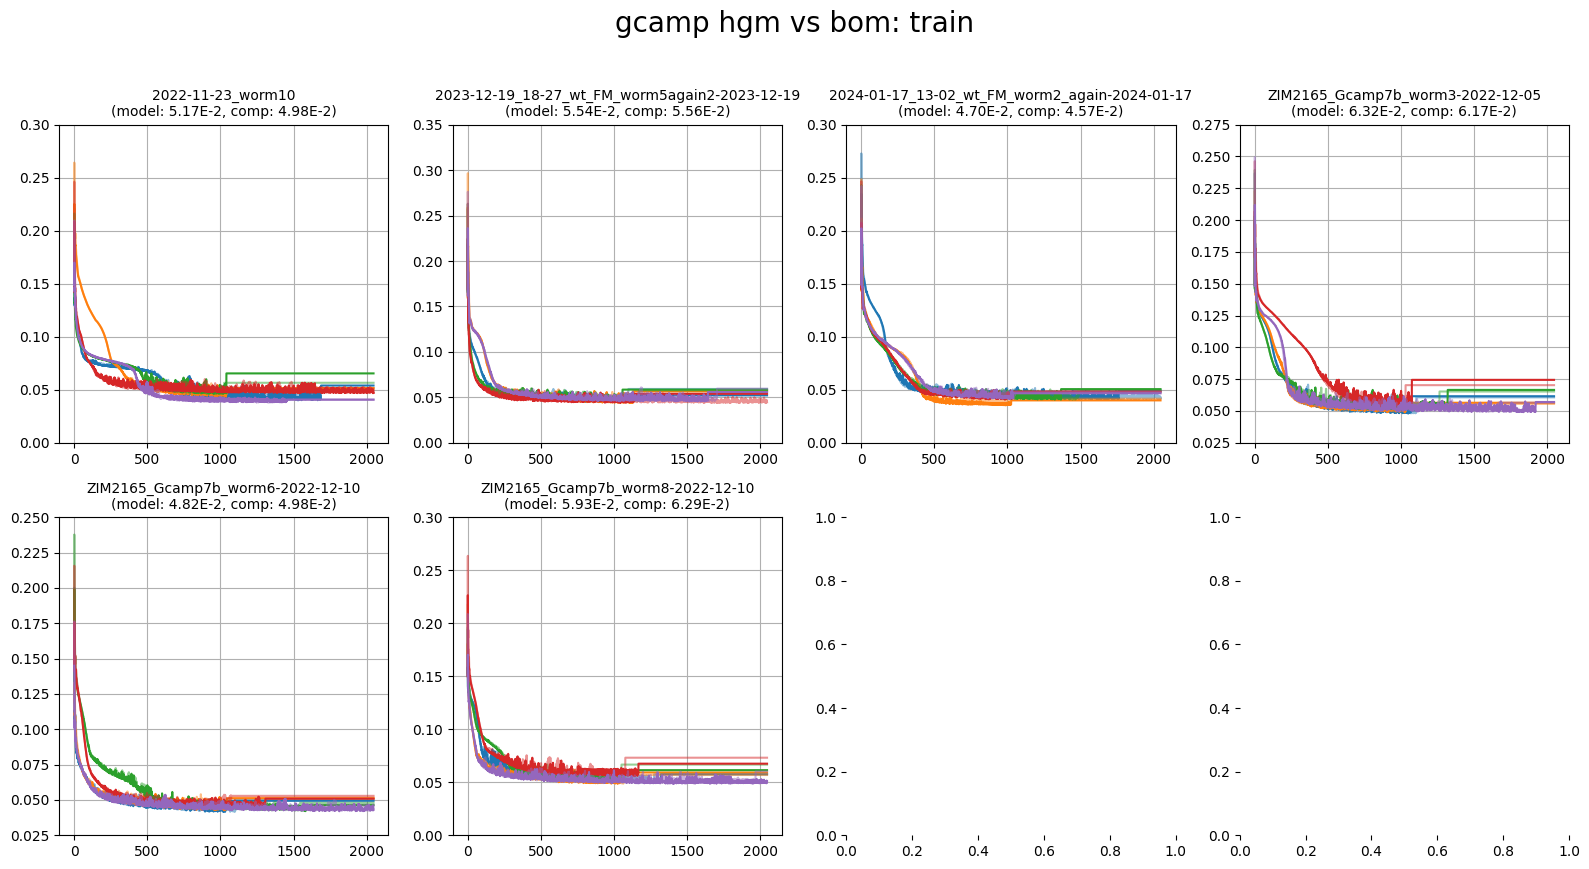

In [19]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: train',
							  filenames_gcamp,
							  hgms_losses_train_gcamp, boms_losses_train_gcamp,
							  ylimits=None)

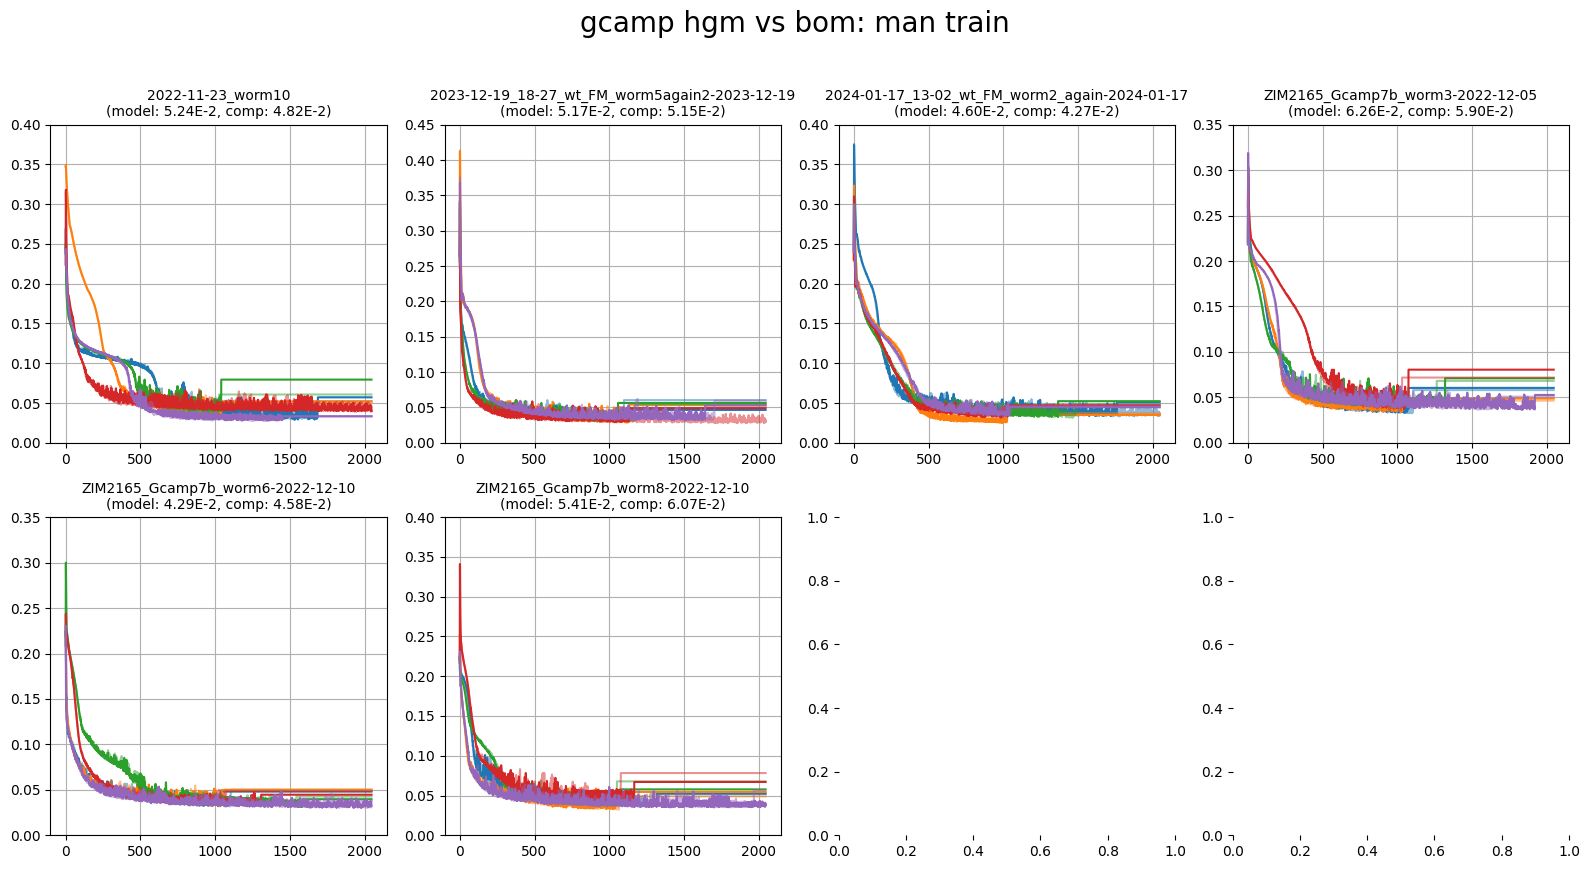

In [20]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: man train',
							  filenames_gcamp,
							  hgms_man_losses_train_gcamp, boms_man_losses_train_gcamp,
							  ylimits=None)

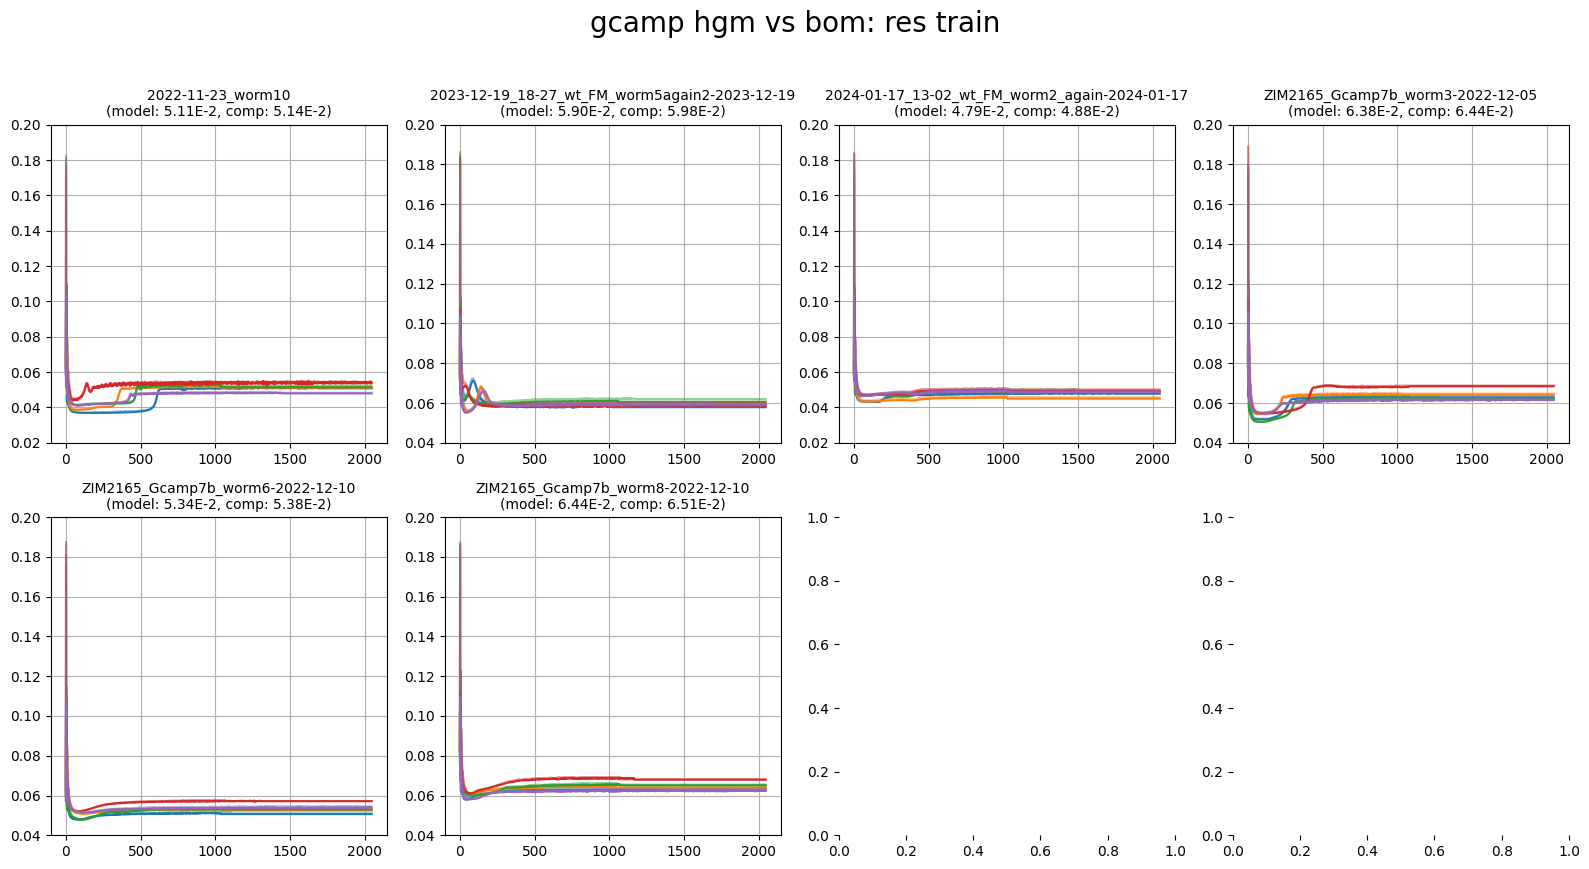

In [21]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: res train',
							  filenames_gcamp,
							  hgms_res_losses_train_gcamp, boms_res_losses_train_gcamp,
							  ylimits=None)

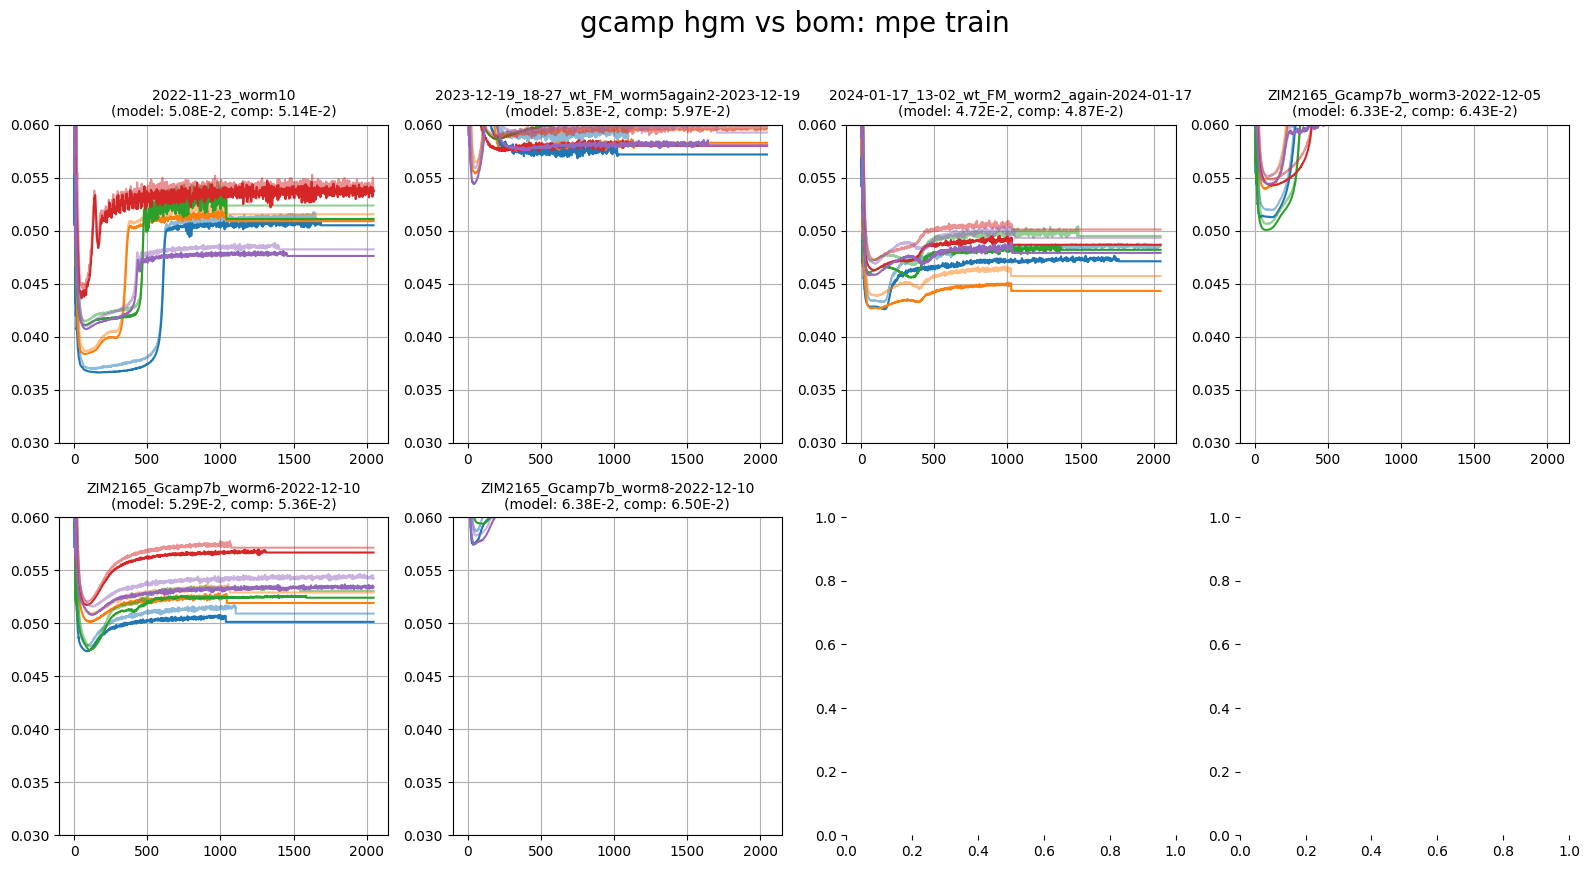

In [33]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe train',
							  filenames_gcamp,
							  hgms_mpe_losses_train_gcamp, boms_mpe_losses_train_gcamp,
							  ylimits=(0.03, 0.06))

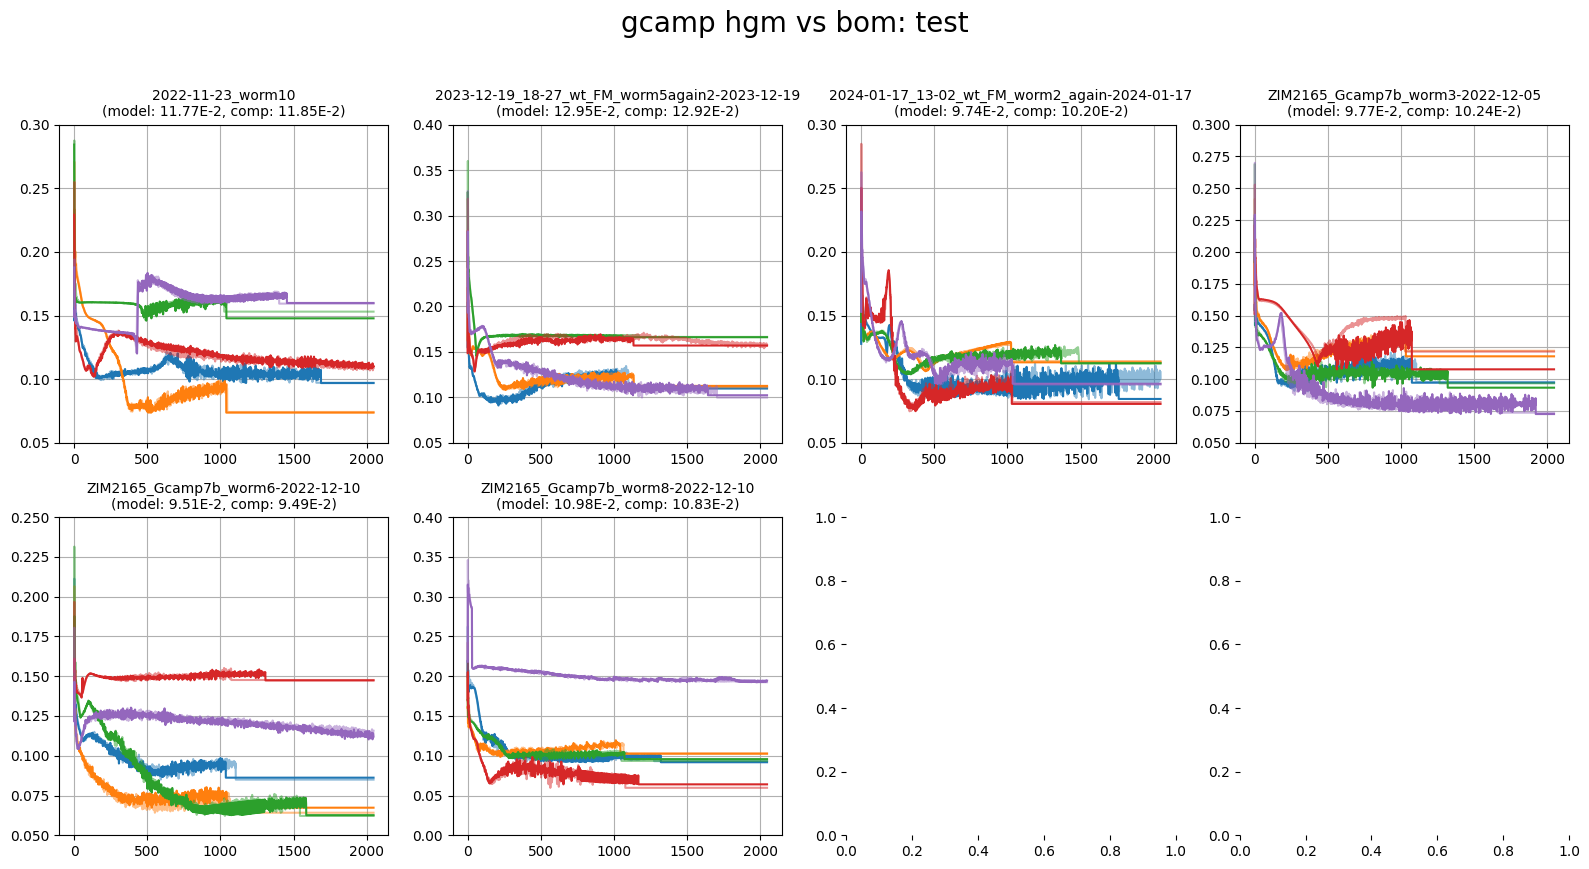

In [23]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: test',
							  filenames_gcamp,
							  hgms_losses_gcamp, boms_losses_gcamp,
							  ylimits=None)

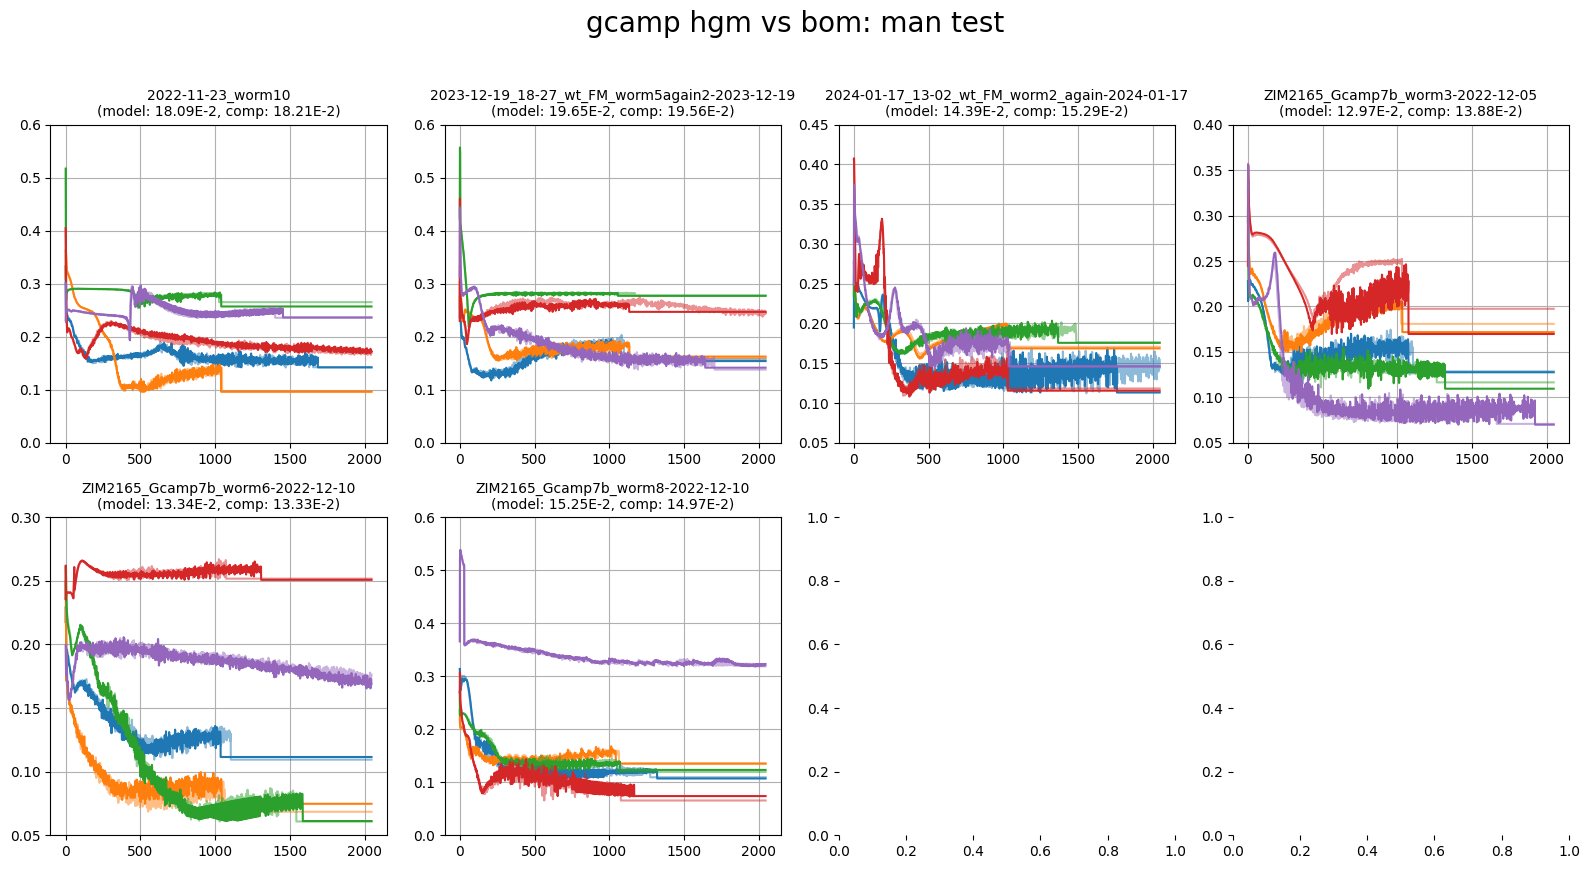

In [24]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: man test',
							  filenames_gcamp,
							  hgms_man_losses_gcamp, boms_man_losses_gcamp,
							  ylimits=None)

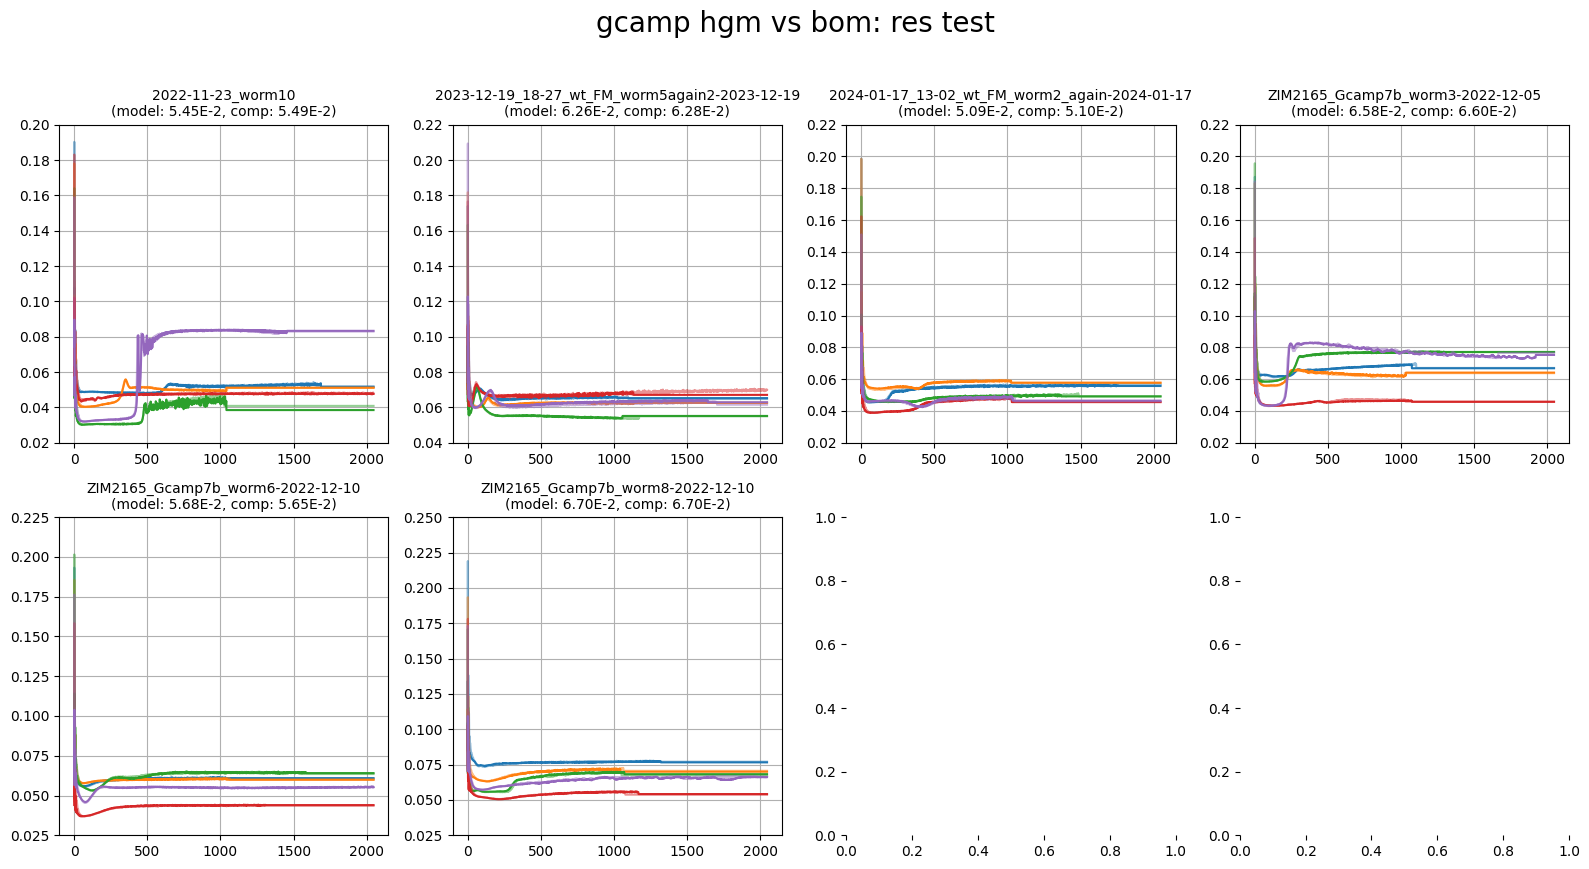

In [25]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: res test',
							  filenames_gcamp,
							  hgms_res_losses_gcamp, boms_res_losses_gcamp,
							  ylimits=None)

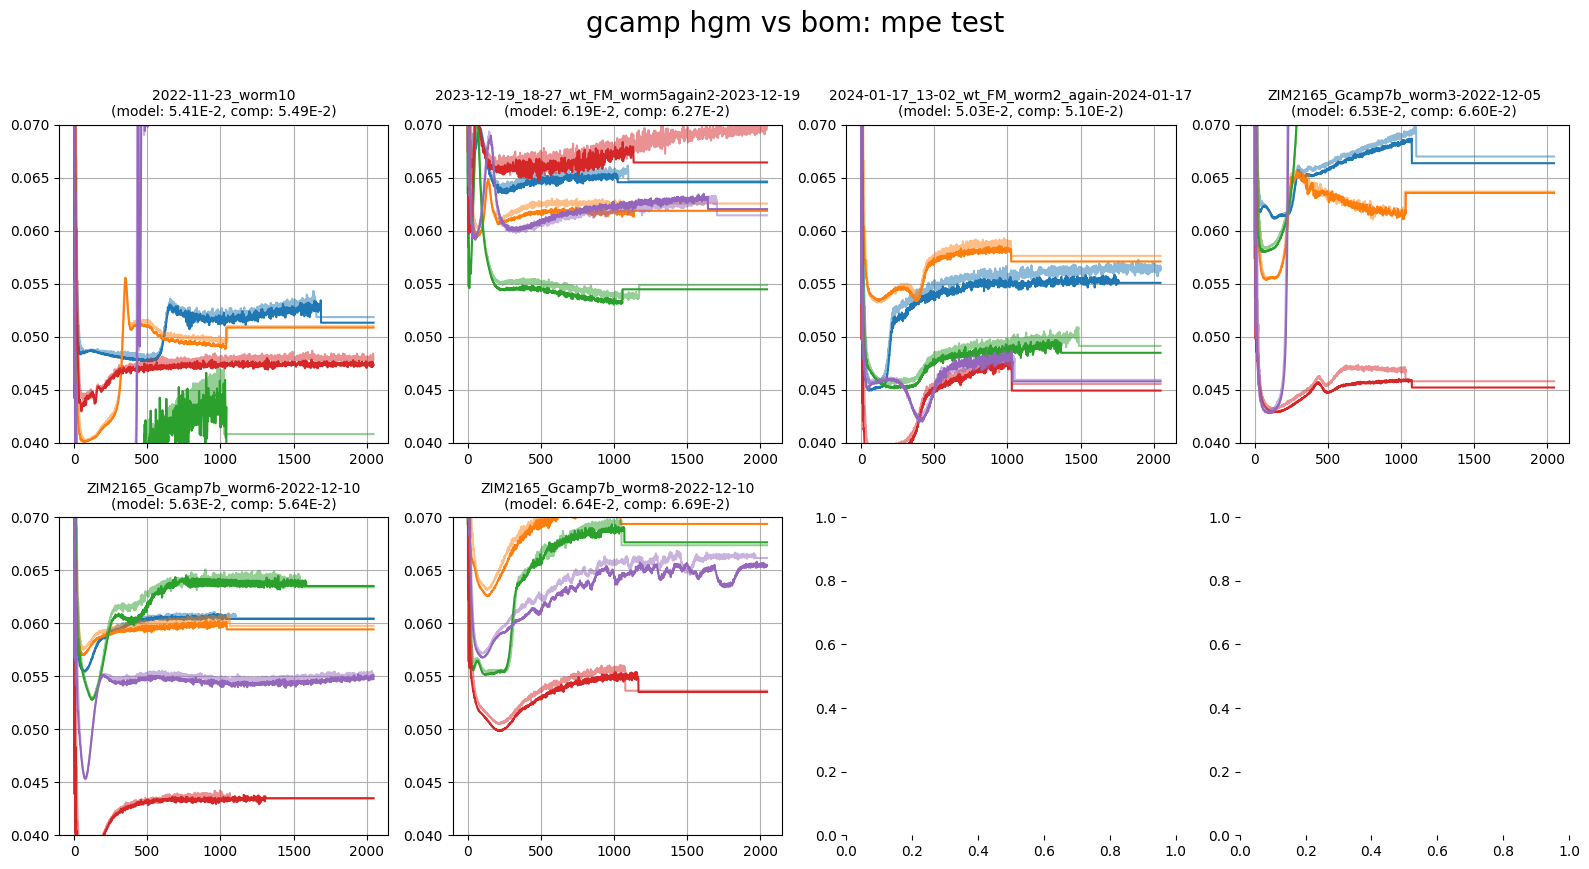

In [34]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe test',
							  filenames_gcamp,
							  hgms_mpe_losses_gcamp, boms_mpe_losses_gcamp,
							  ylimits=(0.04, 0.07))

# GFP

In [27]:
# if gfp:
# 	plot_utils.plot_traces(f'[{filenames_gfp[file_ids_gfp.index(plot_id_gfp)]}] gfp neural traces residual',
# 						   discrete_states_gfp[file_ids_gfp.index(plot_id_gfp)]['REV'],
# 						   traces_gfp[file_ids_gfp.index(plot_id_gfp)][['VB02', 'AVAR']],
# 						   plots_per_row=1, ylimits=None)

### BOM

In [28]:
if gfp:
	(boms_params_gfp,
	 boms_losses_train_gfp, boms_man_losses_train_gfp, boms_res_losses_train_gfp, boms_mpe_losses_train_gfp,
	 boms_losses_gfp, boms_man_losses_gfp, boms_res_losses_gfp, boms_mpe_losses_gfp,
	 boms_scores_per_neuron_gfp) = train_models(bom,
												filenames_gfp,
												discrete_states_gfp,
												eigenworms_gfp,
												traces_gfp,
												hyperparams=bom_reg_lamdas,
												save_name=f'bom_gfp_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')  #save_name=None


1/8: ZIM2319_GFP_worm1-2022-12-10 Split 0 completed. Stopped after 1030 epochs: Split 1 completed. Stopped after 1270 epochs: Split 2 completed. Stopped after 1213 epochs: Split 3 completed. Stopped after 1281 epochs: Split 4 completed. 
2/8: ZIM2319_GFP_worm2-2022-12-10 Split 0 completed. Split 1 completed. Split 2 completed. Stopped after 1066 epochs: Split 3 completed. Stopped after 1980 epochs: Split 4 completed. 
3/8: ZIM2319_GFP_worm3-2022-12-10 Stopped after 1025 epochs: Split 0 completed. Stopped after 1473 epochs: Split 1 completed. Stopped after 1615 epochs: Split 2 completed. Stopped after 1116 epochs: Split 3 completed. Split 4 completed. 
4/8: ZIM2319_GFP_worm4-2022-12-10 Stopped after 1169 epochs: Split 0 completed. Stopped after 1045 epochs: Split 1 completed. Split 2 completed. Split 3 completed. Stopped after 1090 epochs: Split 4 completed. 
5/8: ZIM2319_GFP_worm5-2022-12-10 Stopped after 1812 epochs: Split 0 completed. Stopped after 1827 epochs: Split 1 completed. Sp

### HGM

In [29]:
if gfp:
	(hgms_params_gfp,
	 hgms_losses_train_gfp, hgms_man_losses_train_gfp, hgms_res_losses_train_gfp, hgms_mpe_losses_train_gfp,
	 hgms_losses_gfp, hgms_man_losses_gfp, hgms_res_losses_gfp, hgms_mpe_losses_gfp,
	 hgms_scores_per_neuron_gfp) = train_models(hgm,
												filenames_gfp,
												discrete_states_gfp,
												eigenworms_gfp,
												traces_gfp,
												hyperparams=hgm_reg_lamdas,
												save_name=f'hgm_gfp_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')  #save_name=None


1/8: ZIM2319_GFP_worm1-2022-12-10 Split 0 completed. Stopped after 1113 epochs: Split 1 completed. Stopped after 1132 epochs: Split 2 completed. Stopped after 1164 epochs: Split 3 completed. Stopped after 1823 epochs: Split 4 completed. 
2/8: ZIM2319_GFP_worm2-2022-12-10 Stopped after 1614 epochs: Split 0 completed. Stopped after 1122 epochs: Split 1 completed. Split 2 completed. Stopped after 1104 epochs: Split 3 completed. Stopped after 1148 epochs: Split 4 completed. 
3/8: ZIM2319_GFP_worm3-2022-12-10 Stopped after 1038 epochs: Split 0 completed. Split 1 completed. Split 2 completed. Stopped after 1235 epochs: Split 3 completed. Split 4 completed. 
4/8: ZIM2319_GFP_worm4-2022-12-10 Stopped after 1063 epochs: Split 0 completed. Stopped after 1077 epochs: Split 1 completed. Stopped after 1764 epochs: Split 2 completed. Stopped after 1995 epochs: Split 3 completed. Stopped after 1031 epochs: Split 4 completed. 
5/8: ZIM2319_GFP_worm5-2022-12-10 Stopped after 1044 epochs: Split 0 compl

### losses

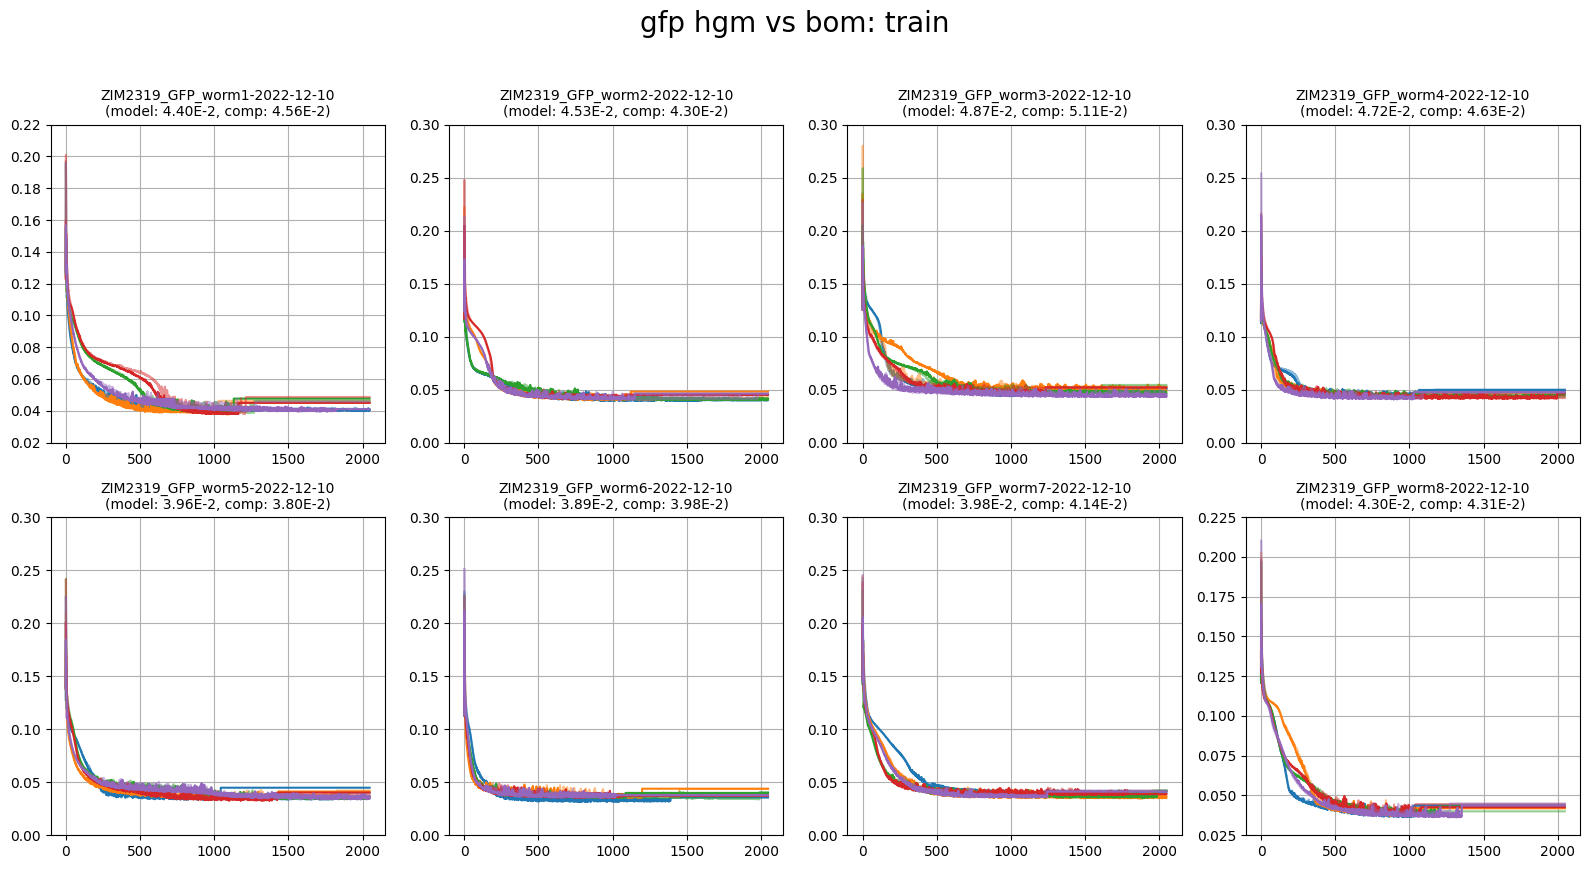

In [30]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: train',
								  filenames_gfp,
								  hgms_losses_train_gfp, boms_losses_train_gfp,
								  ylimits=None)

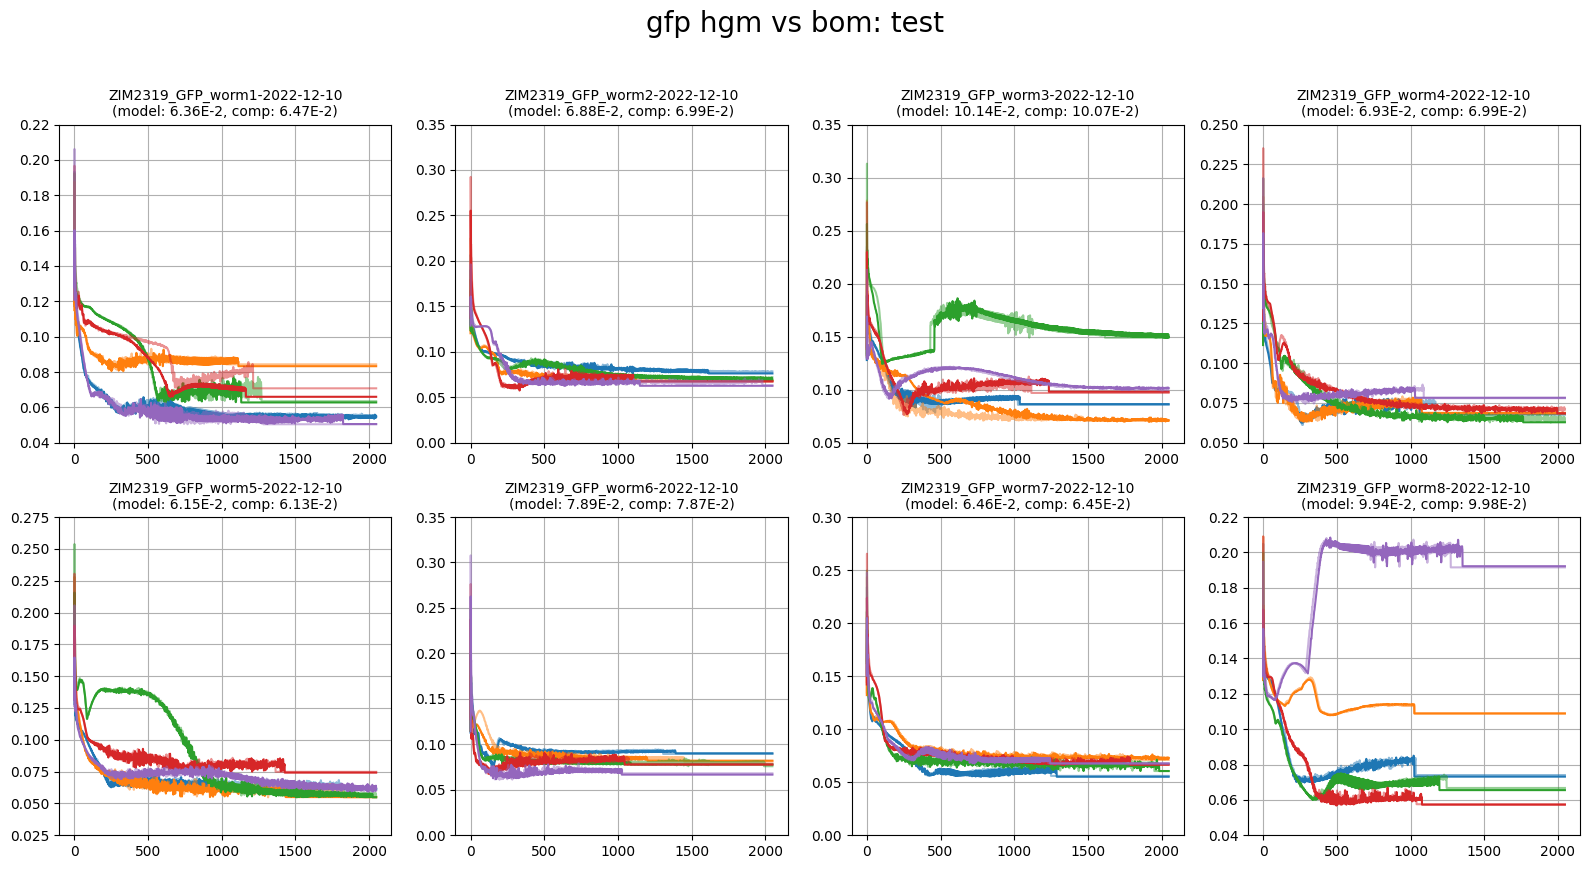

In [31]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: test',
								  filenames_gfp,
								  hgms_losses_gfp, boms_losses_gfp,
								  ylimits=None)

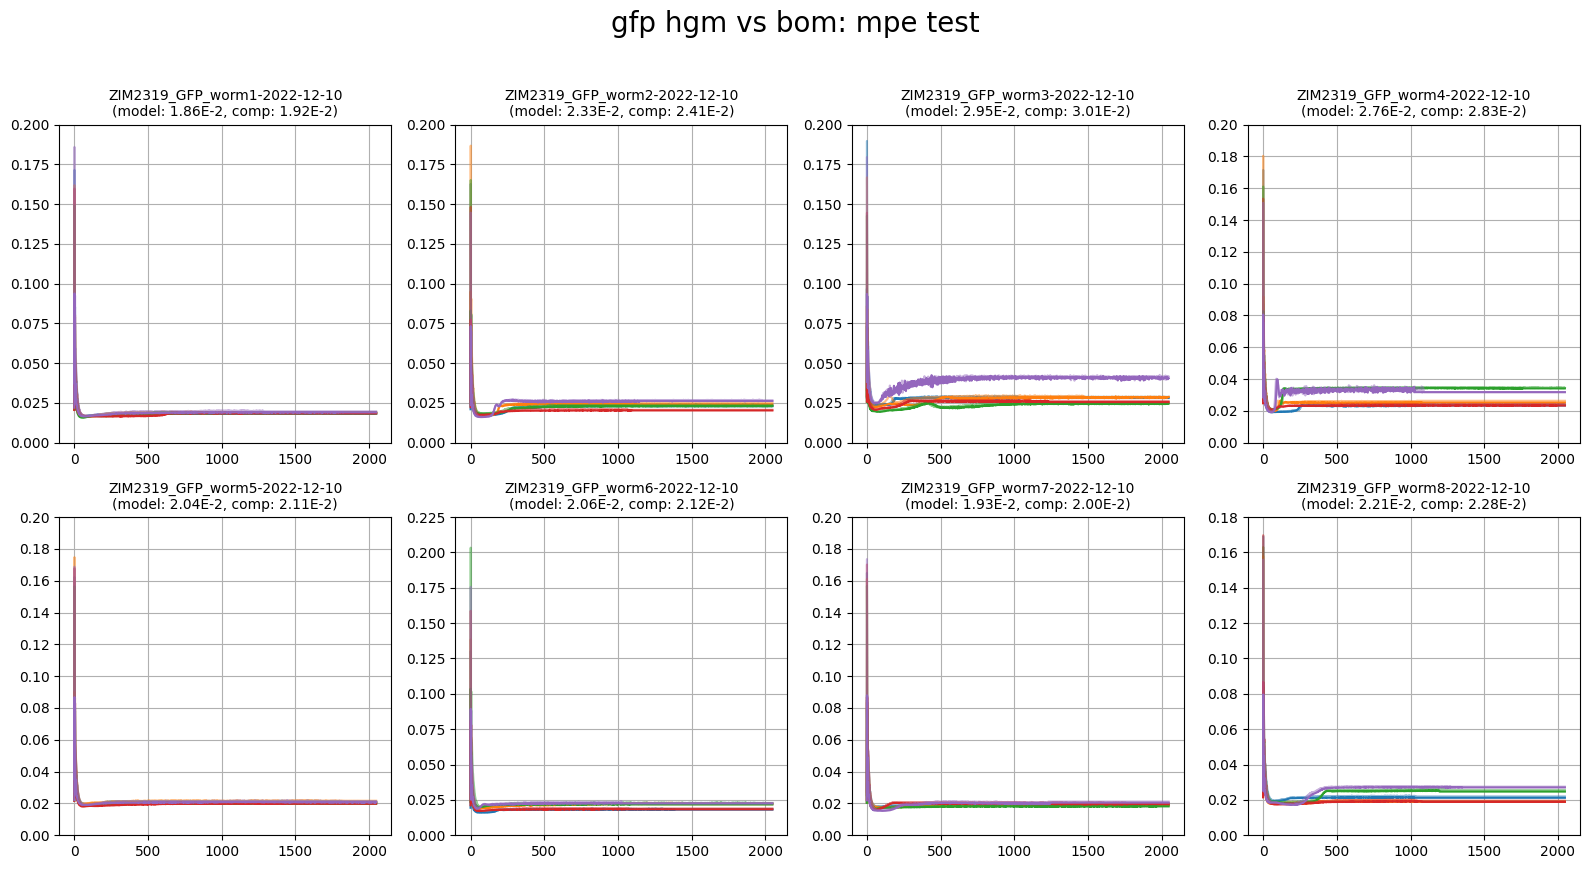

In [32]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: mpe test',
								  filenames_gfp,
								  hgms_mpe_losses_gfp, boms_mpe_losses_gfp,
								  ylimits=None)